# 02 共同更新の学習率倍率・往復数・局所更新回数

このNotebookは、TT pair の結合テンソル `T` と通常 parameter を同時に更新する学習について、次の3つを変えて比べる。

- 共同更新全体の step 幅（`JOINT_LEARNING_RATE_MULTIPLIER`）
- 最大往復数 `MAX_SWEEPS`
- 1 pair あたりの局所更新回数 `LOCAL_STEPS_PER_PAIR`

更新対象は全条件で同じである。`T`、`fc1.bias`、`fc2`、`fc3` を更新し、対象 pair 以外の TT core はその局所更新では固定する。更新なし、TT だけ、通常 parameter だけ、という切り分けはしない。

したがって、損失や accuracy が動いても、それを TT 更新だけの効果とは読まない。二つの学習率は基準値を同じにして倍率で連動させている。これは探索範囲を12条件に限るための制約であり、最適な学習率が両者で同じだという主張ではない。どちら側の学習率が改善に寄与したかも、この実験では分からない。

初期状態は、01が保存した stage C（`initial_stage_c.pt`）を全条件で読み直す。これは同じ初期 dense モデルを TT-SVD と rank 上限に通し、site 0 へ正準化し、スケール補正をしなかった状態である。01では正準化の前後で実効重みと logits が合い、対象外の state が一致し、重み・出力・勾配が有限であることを確認している。学習性能が最適だと示された初期化ではない。

00が保存した checkpoint と、この stage C が同じ state だとは仮定しない。00との差を、初期状態まで一致した比較としては読まない。

既定では本実験の12条件は開始しない。`RUN_FULL_GRID = False` のまま実行すると、全12条件は未実行と表示する。smoke run は本実験の完了ではない。

文書との違いを、ここで固定しておく。

- 01の本文は、01の作業範囲として学習ループを作らないと書いている。これは01を診断に限る宣言であり、02の目的を別実験へ変える指示ではない。
- `docs/40_TT_MPS_NN圧縮/10_FashionMNIST_MLP/10_full-batch_2-core_sweep実験結果と考察.md` の節6は、更新対象の ablation、往復数、pair 内 step、二つの学習率を別々の実験に分ける順序を提案している。今回は共同更新のまま、倍率・最大往復数・局所更新回数の12条件を比べる。節6の比較Aは行わない。既存文書は変更しない。


## 1. 設定

絶対学習率は、基準値に倍率を掛けたものである。

$$
\eta_{\mathrm{tt}} = m \, \eta_{\mathrm{tt}}^{\mathrm{base}}, \qquad
\eta_{\mathrm{dense}} = m \, \eta_{\mathrm{dense}}^{\mathrm{base}}.
$$

今回は両方の基準が $10^{-3}$ なので、倍率 1、10、100 の絶対学習率は両方とも 0.001、0.01、0.1 になる。

6 core の1往復は、右向き5 pair と左向き5 pair で 10 pair 訪問である。各 pair で局所更新を $L$ 回行うと、正常完了した1往復の成功更新数は $10L$ である。全データ勾配の計算回数は、往復数 $S$ に対して

$$
U = 10LS
$$

である。内訳は、$(S,L)=(5,1)$ で50回、$(5,4)$ で200回、$(20,1)$ で200回、$(20,4)$ で800回。12条件の合計は3750回で、00の50回に対する勾配計算回数の比は75である。評価、SVD、候補検証、保存の時間は別なので、壁時計時間が75倍になるとは読まない。

同じ200回でも、5往復・local step 4 と 20往復・local step 1 では評価回数が違う。実行時間が同じとは読まない。

改善停滞による early stopping は無効にする。指定した最大往復数まで進む。非有限な損失・勾配・更新候補、または SVD の数値失敗のときは、その条件だけを異常終了として残し、失敗した候補は commit しない。`ValueError` や `AssertionError` などの実装例外は、数値異常へ読み替えずに止める。

best は、往復が終わって評価した validation loss の過去最小である。初期状態も含む。`min_delta` では判定しない。長い実行ほど best の候補を多く観測する。最大往復数の比較では final を主に見て、best は別に報告する。


In [17]:
import csv
import hashlib
import json
import math
import os
import statistics
import sys
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import torch
from matplotlib import font_manager
from torch import nn
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import TTLinear
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    split_fashion_mnist_dataset,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import (
    evaluate,
    load_condition_summary,
    load_tt_linear_sweep_checkpoint,
    run_resumable_condition_grid,
    save_tt_linear_full_batch_sweep_run,
    train_tt_linear_full_batch_sweeps,
)
from nn_compression.tt_mps import tt_matrix_canonicality_errors
from nn_compression.utils import find_project_root, get_experiment_dirs, set_seed

# 本実験の12条件は、このスイッチが True のときだけ開始する。
RUN_FULL_GRID = True
# 実データ上の短い確認。12条件とは別ディレクトリへ書く。
RUN_SMOKE = False

SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK_CAP = 12
EXPECTED_INITIAL_RANKS = (1, 8, 12, 12, 12, 12, 1)
LAYER_NAME = "fc1"
BATCH_SIZE = 512
DIAGNOSTIC_BATCH_SIZE = 512
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
BASE_TT_PAIR_LEARNING_RATE = 1e-3
BASE_DENSE_PARAMETER_LEARNING_RATE = 1e-3
JOINT_LEARNING_RATE_MULTIPLIERS = [1.0, 10.0, 100.0]
MAX_SWEEPS_LIST = [5, 20]
LOCAL_STEPS_LIST = [1, 4]
SMOKE_MAX_SWEEPS = 1
SMOKE_LOCAL_STEPS = 1
# 無効化はフラグで行う。patience を巨大にして代用しない。
# フラグが False のとき、この patience は停止判定に使われない。
EARLY_STOPPING_PATIENCE = 1
EARLY_STOPPING_MIN_DELTA = 0.0
EARLY_STOPPING_ENABLED = False

assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784
assert len(OUT_MODES) == 6
assert BASE_TT_PAIR_LEARNING_RATE == BASE_DENSE_PARAMETER_LEARNING_RATE == 1e-3
assert JOINT_LEARNING_RATE_MULTIPLIERS == [1.0, 10.0, 100.0]
assert MAX_SWEEPS_LIST == [5, 20]
assert LOCAL_STEPS_LIST == [1, 4]

project_root = find_project_root(Path.cwd())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INITIAL_CHECKPOINT = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "01_tt_initialization_scale_diagnostics"
    / "initial_stage_c.pt"
)
_, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    "02_full_batch_sweep_update_budget_grid",
)
_, smoke_models_dir, smoke_results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    "02_full_batch_sweep_update_budget_grid_smoke_bs512",
)

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic", "Noto Sans CJK JP"):
    if any(font.name == font_name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break

print("device:", DEVICE)
print("dtype: torch.float32（MNISTMLP と checkpoint の想定）")
print("RUN_FULL_GRID:", RUN_FULL_GRID)
print("RUN_SMOKE:", RUN_SMOKE)
print("batch size:", BATCH_SIZE)
print("initial checkpoint:", INITIAL_CHECKPOINT)
print("full grid models:", models_dir)
print("smoke models:", smoke_models_dir)


device: cuda
dtype: torch.float32（MNISTMLP と checkpoint の想定）
RUN_FULL_GRID: True
RUN_SMOKE: False
batch size: 512
initial checkpoint: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\01_tt_initialization_scale_diagnostics\initial_stage_c.pt
full grid models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\02_full_batch_sweep_update_budget_grid
smoke models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\02_full_batch_sweep_update_budget_grid_smoke_bs512


## 2. データと共通初期状態

前処理は `ToTensor` だけ、分割は seed 0 の 50,000 / 5,000 / 5,000 である。最後の 5,000 件は rank 選択用なので、このNotebookでは走査しない。test も走査しない。early-stopping 用の 5,000 件は、停止には使わず、開発・設定選択用の validation として往復終了後に評価する。

minibatch は全学習データの平均勾配を分割して足すために使う。minibatch ごとに parameter は更新しない。

モデルの骨格は checkpoint の core から作る。seed から TT-SVD をやり直して初期重みにはしない。ファイルが無い場合は、ここで止める。読み込んだ modes、rank cap、中心 site、rank 列、正準誤差、tensor 値がファイルと合わなければ止める。実行後に、共通 checkpoint の sha256 が変わっていないことを確認する。


In [18]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def condition_id(multiplier, max_sweeps, local_steps):
    return f"jointx{multiplier:g}_s{max_sweeps}_l{local_steps}"


ALL_CONDITION_IDS = [
    condition_id(multiplier, max_sweeps, local_steps)
    for multiplier in JOINT_LEARNING_RATE_MULTIPLIERS
    for max_sweeps in MAX_SWEEPS_LIST
    for local_steps in LOCAL_STEPS_LIST
]
assert len(ALL_CONDITION_IDS) == 12
assert len(set(ALL_CONDITION_IDS)) == 12

if not INITIAL_CHECKPOINT.is_file():
    raise FileNotFoundError(
        "共通初期 checkpoint がありません。初期化し直さずに停止します: "
        f"{INITIAL_CHECKPOINT}"
    )
SHARED_CHECKPOINT_SHA256 = file_sha256(INITIAL_CHECKPOINT)

fashion_root = project_root / "data" / "FashionMNIST" / "raw"
required_files = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]
missing_files = [name for name in required_files if not (fashion_root / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        "Fashion-MNIST がありません。代替データでは実行しません: " + ", ".join(missing_files)
    )

set_seed(SEED)
full_train, test_dataset = get_fashion_mnist_datasets(
    project_root / "data",
    download=False,
)
train_dataset, early_stopping_dataset, rank_selection_dataset = split_fashion_mnist_dataset(
    full_train,
    SPLIT_LENGTHS,
    seed=SEED,
)
gradient_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
validation_loader = DataLoader(
    early_stopping_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)
diagnostic_images = torch.stack(
    [train_dataset[index][0] for index in range(DIAGNOSTIC_BATCH_SIZE)]
)
diagnostic_labels = torch.tensor(
    [int(train_dataset[index][1]) for index in range(DIAGNOSTIC_BATCH_SIZE)],
    dtype=torch.long,
)
criterion = nn.CrossEntropyLoss()

print("train / early-stopping validation / rank-selection:", len(train_dataset), len(early_stopping_dataset), len(rank_selection_dataset))
print("test is not scanned:", len(test_dataset))
print("rank-selection validation is not scanned:", len(rank_selection_dataset))
print("diagnostic batch:", tuple(diagnostic_images.shape))
print("checkpoint sha256:", SHARED_CHECKPOINT_SHA256)


def _core_keys(state):
    prefix = f"{LAYER_NAME}.cores."
    return sorted(
        (key for key in state if key.startswith(prefix)),
        key=lambda key: int(key.rsplit(".", 1)[-1]),
    )


def assert_checkpoint_contract(payload):
    if payload.get("layer_name") != LAYER_NAME:
        raise ValueError(f"layer_name が一致しません: {payload.get('layer_name')!r}")
    if tuple(payload.get("out_modes", ())) != OUT_MODES:
        raise ValueError(f"out_modes が一致しません: {payload.get('out_modes')!r}")
    if tuple(payload.get("in_modes", ())) != IN_MODES:
        raise ValueError(f"in_modes が一致しません: {payload.get('in_modes')!r}")
    if int(payload.get("rank_cap", -1)) != RANK_CAP:
        raise ValueError(f"rank_cap が一致しません: {payload.get('rank_cap')!r}")
    if int(payload.get("canonical_center", -1)) != 0:
        raise ValueError(
            f"canonical_center は 0 である必要があります: {payload.get('canonical_center')!r}"
        )
    if payload.get("stage") != "C":
        raise ValueError(f"stage C ではありません: {payload.get('stage')!r}")
    if int(payload.get("seed", -1)) != SEED:
        raise ValueError(f"seed が一致しません: {payload.get('seed')!r}")


def build_model_from_checkpoint(path):
    payload = torch.load(Path(path), map_location="cpu", weights_only=False)
    assert_checkpoint_contract(payload)
    state = payload["state_dict"]
    keys = _core_keys(state)
    if len(keys) != len(OUT_MODES):
        raise ValueError(f"core 数が一致しません: {len(keys)}")
    cores = [state[key].detach().to(dtype=torch.float32, device="cpu") for key in keys]
    ranks = (int(cores[0].shape[0]),) + tuple(int(core.shape[-1]) for core in cores)
    if ranks != EXPECTED_INITIAL_RANKS:
        raise ValueError(f"初期 rank 列が一致しません: {ranks}")
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, 0)
    if errors["left"]:
        raise ValueError("site 0 正準のはずが、左側の直交誤差があります。")
    ortho_error = max(float(item) for item in errors["right"])
    if ortho_error > 1e-4:
        raise ValueError(f"site 0 の右直交誤差が大きすぎます: {ortho_error}")
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state[f"{LAYER_NAME}.bias"].detach())
    own = dict(model.named_parameters())
    if set(own) != set(state):
        raise ValueError(
            "checkpoint とモデルの parameter 名が一致しません: "
            f"extra={sorted(set(own) - set(state))} missing={sorted(set(state) - set(own))}"
        )
    with torch.no_grad():
        for key, value in state.items():
            if key.startswith(f"{LAYER_NAME}.cores.") or key == f"{LAYER_NAME}.bias":
                continue
            own[key].copy_(value)
    loaded = model.state_dict()
    for key, value in state.items():
        if loaded[key].dtype != torch.float32:
            raise TypeError(f"{key} の dtype が float32 ではありません: {loaded[key].dtype}")
        if not torch.equal(loaded[key].cpu(), value.detach().to(dtype=torch.float32, device="cpu")):
            raise ValueError(f"初期 state が checkpoint と一致しません: {key}")
    model.to(DEVICE)
    for core in model.fc1.cores:
        core.requires_grad_(False)
    moved = model.state_dict()
    for key, value in state.items():
        target = value.detach().to(dtype=torch.float32, device=DEVICE)
        if not torch.equal(moved[key], target):
            raise ValueError(f"device へ移した初期 state が checkpoint と一致しません: {key}")
    return model, ortho_error


probe_model, initial_ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
    raise RuntimeError("checkpoint を読んだだけで共通ファイルの内容が変わりました。")
print("initial ranks:", EXPECTED_INITIAL_RANKS)
print("site-0 right orthogonality max error:", initial_ortho_error)
print("module:", type(probe_model.fc1).__name__, type(probe_model.fc2).__name__, type(probe_model.fc3).__name__)
del probe_model


train / early-stopping validation / rank-selection: 50000 5000 5000
test is not scanned: 10000
rank-selection validation is not scanned: 5000
diagnostic batch: (512, 1, 28, 28)
checkpoint sha256: ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a
initial ranks: (1, 8, 12, 12, 12, 12, 1)
site-0 right orthogonality max error: 9.382572443428217e-07
module: TTLinear Linear Linear


## 3. 1条件の実行

各条件は、共通 checkpoint からモデルを作り直し、学習管理状態も新しくする。前の条件の重み、成功回数、pair、best、履歴は渡さない。

1回の局所更新は、既存の `train_tt_linear_full_batch_sweeps` が行う。最新の pair から独立な `T` を作り、全学習データの平均 cross-entropy の勾配を集計し、`T` と通常 parameter の候補を作る。進行方向に応じた SVD と rank 上限で分割し、形状・dtype・device・有限性を確認してから commit する。同じ `T` を複数回更新して最後だけ SVD する処理は入っていない。同じ pair を繰り返すときも、毎 step で core から `T` を作り、勾配を計算し直す。通常 parameter も毎 step で更新する。毎 step で鎖全体を正準化し直す処理は加えない。

往復が終わったあと、固定したモデルを通常 forward で評価する。勾配を集計したときの損失は、その評価値として使わない。

final は、予算を終えたモデル、または異常終了時に残った最後の正常状態である。途中の往復は完了数に入れない。best は往復終了時の評価だけから選ぶ。final を保存してから、別の読み込みで best を確認する。

数値異常で返った条件は記録して次へ進む。想定外の例外は捕捉しない。既存の条件ディレクトリにファイルがある場合は、上書きせずに止める。


In [19]:
SUMMARY_FIELDS = [
    "condition_id",
    "status",
    "batch_size",
    "joint_learning_rate_multiplier",
    "base_tt_pair_learning_rate",
    "base_dense_parameter_learning_rate",
    "tt_pair_learning_rate",
    "dense_parameter_learning_rate",
    "max_sweeps",
    "local_steps_per_pair",
    "requested_full_data_gradient_passes",
    "completed_sweeps",
    "successful_local_updates",
    "incomplete_sweep_successes",
    "stop_reason",
    "stop_detail",
    "stop_sweep",
    "stop_pair",
    "stop_direction",
    "stop_local_step",
    "initial_train_loss",
    "initial_train_acc",
    "initial_validation_loss",
    "initial_validation_acc",
    "final_train_loss",
    "final_train_acc",
    "final_validation_loss",
    "final_validation_acc",
    "final_is_completed_budget",
    "best_sweep",
    "best_train_loss",
    "best_train_acc",
    "best_validation_loss",
    "best_validation_acc",
    "seconds_load",
    "seconds_train",
    "seconds_save",
    "seconds_total",
    "timing_window",
    "checkpoint_sha256",
    "checkpoint_path",
    "max_tt_relative_update",
    "max_dense_relative_update",
    "reloaded_final_validation_loss",
    "reloaded_final_validation_acc",
    "reloaded_best_validation_loss",
    "reloaded_best_validation_acc",
]


def _history_row(result, sweep):
    matches = [row for row in result.history if int(row["sweep"]) == sweep]
    if len(matches) != 1:
        raise RuntimeError(f"sweep {sweep} の評価行が一意ではありません。")
    return matches[0]


def _finite_metric(value, name):
    number = float(value)
    if not math.isfinite(number):
        raise ValueError(f"{name} が有限ではありません: {number}")
    return number


def run_condition(multiplier, max_sweeps, local_steps, output_models):
    label = condition_id(multiplier, max_sweeps, local_steps)
    directory = Path(output_models) / label
    if directory.exists() and any(directory.iterdir()):
        raise FileExistsError(f"既存結果があるため上書きしません: {directory}")
    if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
        raise RuntimeError("学習前に共通 checkpoint の内容が変わっています。")

    synchronize()
    started = time.perf_counter()
    model, _ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
    synchronize()
    loaded = time.perf_counter()
    result = train_tt_linear_full_batch_sweeps(
        model,
        gradient_loader,
        train_eval_loader,
        validation_loader,
        layer_name=LAYER_NAME,
        rank_cap=RANK_CAP,
        tt_pair_learning_rate=multiplier * BASE_TT_PAIR_LEARNING_RATE,
        dense_parameter_learning_rate=multiplier * BASE_DENSE_PARAMETER_LEARNING_RATE,
        max_sweeps=max_sweeps,
        local_steps_per_pair=local_steps,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
        early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
        early_stopping_enabled=EARLY_STOPPING_ENABLED,
        diagnostic_images=diagnostic_images,
        diagnostic_labels=diagnostic_labels,
        device=DEVICE,
        center=0,
        criterion=criterion,
    )
    synchronize()
    trained = time.perf_counter()
    if result.stop_reason == "early_stopping":
        raise RuntimeError("early stopping を無効化したのに early_stopping で止まりました。")
    if result.stop_reason not in {"max_sweeps", "non_finite", "svd_failure"}:
        raise RuntimeError(f"想定していない停止理由です: {result.stop_reason}")

    completed_budget = (
        result.stop_reason == "max_sweeps" and result.completed_sweeps == max_sweeps
    )
    initial = _history_row(result, 0)
    best = _history_row(result, result.best_sweep)
    if completed_budget:
        status = "正常完了"
    else:
        if result.stop_reason == "max_sweeps":
            raise RuntimeError("最大往復数まで到達した記録と完了数が一致しません。")
        status = "途中終了"

    config = {
        "model": "MNISTMLP fc1 TTLinear, fc2 Linear, fc3 Linear, ReLU",
        "condition_id": label,
        "initialization": "01 initial_stage_c.pt reloaded for every condition",
        "checkpoint_path": str(INITIAL_CHECKPOINT),
        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
        "layer_name": LAYER_NAME,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "rank_cap": RANK_CAP,
        "expected_initial_ranks": list(EXPECTED_INITIAL_RANKS),
        "seed": SEED,
        "dtype": "torch.float32",
        "batch_size": BATCH_SIZE,
        "joint_learning_rate_multiplier": multiplier,
        "base_tt_pair_learning_rate": BASE_TT_PAIR_LEARNING_RATE,
        "base_dense_parameter_learning_rate": BASE_DENSE_PARAMETER_LEARNING_RATE,
        "tt_pair_learning_rate": multiplier * BASE_TT_PAIR_LEARNING_RATE,
        "dense_parameter_learning_rate": multiplier * BASE_DENSE_PARAMETER_LEARNING_RATE,
        "learning_rates_are_tied_only_to_limit_the_grid": True,
        "max_sweeps": max_sweeps,
        "local_steps_per_pair": local_steps,
        "early_stopping_enabled": EARLY_STOPPING_ENABLED,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
        "split": "Fashion-MNIST 50000/5000/5000 seed 0; train / early-stopping / rank-selection",
        "test_and_rank_selection_are_not_scanned": True,
        "update_targets": "merged pair T, fc1.bias, fc2, fc3",
    }
    save_tt_linear_full_batch_sweep_run(directory, model, result, config)
    synchronize()
    saved = time.perf_counter()
    if file_sha256(INITIAL_CHECKPOINT) != SHARED_CHECKPOINT_SHA256:
        raise RuntimeError("学習または保存のあと、共通 checkpoint の内容が変わりました。")
    if completed_budget:
        final_metrics = _history_row(result, max_sweeps)
    else:
        # 未完了の往復は history へ足さない。時間計測の外で、残った正常状態だけを測る。
        retained_train_loss, retained_train_acc = evaluate(
            model, train_eval_loader, criterion, DEVICE
        )
        retained_validation_loss, retained_validation_acc = evaluate(
            model, validation_loader, criterion, DEVICE
        )
        final_metrics = {
            "train_loss": retained_train_loss,
            "train_acc": retained_train_acc,
            "validation_loss": retained_validation_loss,
            "validation_acc": retained_validation_acc,
        }

    saved_initial = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
    shared = torch.load(INITIAL_CHECKPOINT, map_location="cpu", weights_only=False)
    for key, value in shared["state_dict"].items():
        current = saved_initial["state_dict"][key]
        reference = value.detach().to(dtype=current.dtype, device="cpu")
        if not torch.equal(current.cpu(), reference):
            raise RuntimeError(f"保存した初期 state が共通 checkpoint と一致しません: {key}")

    final_model = build_model_from_checkpoint(INITIAL_CHECKPOINT)[0]
    load_tt_linear_sweep_checkpoint(directory / "final_model.pt", final_model)
    final_model.to(DEVICE)
    for key, value in model.state_dict().items():
        if not torch.equal(final_model.state_dict()[key], value):
            raise RuntimeError(f"final checkpoint の再読込が学習後 state と一致しません: {key}")
    reloaded_validation_loss, reloaded_validation_acc = evaluate(
        final_model, validation_loader, criterion, DEVICE
    )
    best_model = build_model_from_checkpoint(INITIAL_CHECKPOINT)[0]
    load_tt_linear_sweep_checkpoint(directory / "best_model.pt", best_model)
    best_model.to(DEVICE)
    reloaded_best_loss, reloaded_best_acc = evaluate(
        best_model, validation_loader, criterion, DEVICE
    )

    ok_logs = [row for row in result.local_updates if row["status"] == "ok"]
    tt_rel = [float(row["tt_relative_update"]) for row in ok_logs]
    dense_rel = [float(row["dense_relative_update"]) for row in ok_logs]
    row = {
        "condition_id": label,
        "status": status,
        "batch_size": BATCH_SIZE,
        "joint_learning_rate_multiplier": multiplier,
        "base_tt_pair_learning_rate": BASE_TT_PAIR_LEARNING_RATE,
        "base_dense_parameter_learning_rate": BASE_DENSE_PARAMETER_LEARNING_RATE,
        "tt_pair_learning_rate": multiplier * BASE_TT_PAIR_LEARNING_RATE,
        "dense_parameter_learning_rate": multiplier * BASE_DENSE_PARAMETER_LEARNING_RATE,
        "max_sweeps": max_sweeps,
        "local_steps_per_pair": local_steps,
        "requested_full_data_gradient_passes": 10 * local_steps * max_sweeps,
        "completed_sweeps": result.completed_sweeps,
        "successful_local_updates": result.successful_local_updates,
        "incomplete_sweep_successes": result.incomplete_sweep_successes,
        "stop_reason": result.stop_reason,
        "stop_detail": result.stop_detail.replace("\n", " "),
        "stop_sweep": result.stop_sweep,
        "stop_pair": result.stop_pair,
        "stop_direction": result.stop_direction,
        "stop_local_step": result.stop_local_step,
        "initial_train_loss": _finite_metric(initial["train_loss"], "initial_train_loss"),
        "initial_train_acc": _finite_metric(initial["train_acc"], "initial_train_acc"),
        "initial_validation_loss": _finite_metric(initial["validation_loss"], "initial_validation_loss"),
        "initial_validation_acc": _finite_metric(initial["validation_acc"], "initial_validation_acc"),
        "final_train_loss": _finite_metric(final_metrics["train_loss"], "final_train_loss"),
        "final_train_acc": _finite_metric(final_metrics["train_acc"], "final_train_acc"),
        "final_validation_loss": _finite_metric(final_metrics["validation_loss"], "final_validation_loss"),
        "final_validation_acc": _finite_metric(final_metrics["validation_acc"], "final_validation_acc"),
        "final_is_completed_budget": completed_budget,
        "best_sweep": result.best_sweep,
        "best_train_loss": _finite_metric(best["train_loss"], "best_train_loss"),
        "best_train_acc": _finite_metric(best["train_acc"], "best_train_acc"),
        "best_validation_loss": _finite_metric(best["validation_loss"], "best_validation_loss"),
        "best_validation_acc": _finite_metric(best["validation_acc"], "best_validation_acc"),
        "seconds_load": loaded - started,
        "seconds_train": trained - loaded,
        "seconds_save": saved - trained,
        "seconds_total": saved - started,
        "timing_window": "cuda synchronize 後の checkpoint 読込、学習（勾配・SVD・往復後評価を含む）、保存。再読込の確認は含まない",
        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
        "checkpoint_path": str(INITIAL_CHECKPOINT),
        "max_tt_relative_update": max(tt_rel) if tt_rel else None,
        "max_dense_relative_update": max(dense_rel) if dense_rel else None,
        "reloaded_final_validation_loss": float(reloaded_validation_loss),
        "reloaded_final_validation_acc": float(reloaded_validation_acc),
        "reloaded_best_validation_loss": float(reloaded_best_loss),
        "reloaded_best_validation_acc": float(reloaded_best_acc),
    }
    final_gap = abs(float(reloaded_validation_loss) - row["final_validation_loss"])
    best_gap = abs(float(reloaded_best_loss) - row["best_validation_loss"])
    print(label, "reload validation gap final/best:", final_gap, best_gap)
    if final_gap > 1e-5 or best_gap > 1e-5:
        raise RuntimeError(f"{label} の再読込後の validation が保存時の指標から離れています。")
    if not math.isfinite(reloaded_validation_loss) or not math.isfinite(reloaded_best_loss):
        raise RuntimeError(f"{label} の再読込後の loss が有限ではありません。")
    print(
        label,
        status,
        "sweeps",
        result.completed_sweeps,
        "/",
        max_sweeps,
        "updates",
        result.successful_local_updates,
        "seconds",
        round(row["seconds_total"], 3),
    )
    return row


def write_summary(path, rows):
    path = Path(path)
    if path.exists():
        raise FileExistsError(f"一覧 CSV を上書きしません: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=SUMMARY_FIELDS, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def read_summary(path):
    with Path(path).open(newline="", encoding="utf-8") as handle:
        return list(csv.DictReader(handle))


def read_history(path):
    with Path(path).open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    for row in rows:
        for key in (
            "sweep",
            "train_loss",
            "train_acc",
            "validation_loss",
            "validation_acc",
            "cumulative_successful_updates",
        ):
            row[key] = float(row[key])
    return rows


## 4. smoke run

batch size 512 の3条件を新しい保存先で実行し、実測時間から本実験の所要時間を見積もる。batch size 64 の旧smoke成果物は削除も上書きもしない。`smoke_report.json` もbatch size 512専用の保存先へ作る。

ここで実行するのは倍率 1、10、100、最大往復数 1、local step 1 の3条件だけである。それぞれ共通の初期 state から独立に始める。出力先は本実験の12条件と分ける。

時間は、CUDA では計測の前後に `synchronize` してから取る。含めるのは checkpoint の読込、学習（その中の全データ勾配、SVD、往復後の評価）、保存である。再読込して通常 forward で評価し直す確認は、この時間の外で行う。

この3条件が正常でも、絶対学習率 0.1 が 20 往復・local step 4 まで安定だとは読まない。

見積もりは、smoke で分けて測った「1回の train/validation 評価」と「1回の全データ勾配を含む局所更新」から、12条件それぞれの $S$ と $L$ へ足し上げる。local step を 4 にすると勾配回数は増えるが、往復終了後の評価回数は $S$ だけで決まる。勾配回数に比例させるだけの見積もりは、この比率の変化を表さない。全条件が最後まで正常完了する前提であり、途中終了すれば実時間は短くなる。


In [20]:
def estimate_full_grid(rows, eval_pair_seconds):
    usable = []
    for row in rows:
        if row["status"] != "正常完了":
            continue
        if int(row["max_sweeps"]) != 1 or int(row["local_steps_per_pair"]) != 1:
            continue
        step_seconds = (float(row["seconds_train"]) - 2.0 * eval_pair_seconds) / 10.0
        usable.append(step_seconds)
    estimate = {
        "eval_pair_seconds": eval_pair_seconds,
        "grad_step_seconds": usable,
        "assumes_all_twelve_complete": True,
        "includes": "条件ごとの読込・保存の平均、往復終了ごとの評価、局所更新",
    }
    if len(usable) != 3 or any(step <= 0 for step in usable):
        estimate["available"] = False
        estimate["reason"] = "3条件すべての局所更新時間を、評価時間と分けて取り出せていません。"
        return estimate
    mean_step = statistics.mean(usable)
    mean_load = statistics.mean(float(row["seconds_load"]) for row in rows)
    mean_save = statistics.mean(float(row["seconds_save"]) for row in rows)
    total = 0.0
    parts = []
    for multiplier in JOINT_LEARNING_RATE_MULTIPLIERS:
        for max_sweeps in MAX_SWEEPS_LIST:
            for local_steps in LOCAL_STEPS_LIST:
                gradient_passes = 10 * local_steps * max_sweeps
                evaluations = max_sweeps + 1
                seconds = (
                    mean_load
                    + mean_save
                    + evaluations * eval_pair_seconds
                    + gradient_passes * mean_step
                )
                total += seconds
                parts.append(
                    {
                        "condition_id": condition_id(multiplier, max_sweeps, local_steps),
                        "seconds": seconds,
                        "gradient_passes": gradient_passes,
                        "evaluation_pairs": evaluations,
                    }
                )
    estimate.update(
        {
            "available": True,
            "mean_grad_step_seconds": mean_step,
            "min_grad_step_seconds": min(usable),
            "max_grad_step_seconds": max(usable),
            "mean_load_seconds": mean_load,
            "mean_save_seconds": mean_save,
            "total_seconds": total,
            "parts": parts,
            "naive_grad_pass_scaled_train_seconds": statistics.mean(
                float(row["seconds_train"]) for row in rows
            )
            * (3750 / 10),
        }
    )
    return estimate


def print_estimate(estimate):
    print("見積もりの前提: smoke の S=1, L=1 で、学習時間から評価2回分を引いた残りを局所更新10回とみなす。")
    print("L=4 では評価回数は増えない。0.1 の長い実行が安定することは、この見積もりに含まれない。")
    if not estimate.get("available"):
        print("内訳見積もりは作れません:", estimate.get("reason"))
        return
    print(
        "評価1組（train 全体と validation）:",
        round(estimate["eval_pair_seconds"], 3),
        "秒",
    )
    print(
        "局所更新1回:",
        round(estimate["mean_grad_step_seconds"], 3),
        "秒（3条件の範囲",
        round(estimate["min_grad_step_seconds"], 3),
        "から",
        round(estimate["max_grad_step_seconds"], 3),
        "）",
    )
    print("12条件の合計見積もり:", round(estimate["total_seconds"] / 60, 2), "分")
    print(
        "参考: smoke の学習時間を勾配回数の比 3750/10 で伸ばすと",
        round(estimate["naive_grad_pass_scaled_train_seconds"] / 60, 2),
        "分。こちらは評価と勾配の比率が L と S で変わることを反映しない。",
    )


smoke_summary_path = smoke_results_dir / "condition_summary.csv"
smoke_report_path = smoke_results_dir / "smoke_report.json"
if RUN_SMOKE:
    # 既存結果があるのに再実行すると run_condition / write_summary が FileExistsError になる。
    if (
        smoke_report_path.is_file()
        or smoke_summary_path.is_file()
        or any(smoke_models_dir.glob("*"))
    ):
        raise FileExistsError(
            "smoke 結果が既にあります。上書きしません。"
            "保存済みを見るなら RUN_SMOKE = False にしてこのセルを再実行するか、"
            f"再計測するなら {smoke_models_dir} と {smoke_results_dir} を消してから "
            "RUN_SMOKE = True で実行してください。"
        )
    print("smoke run を実行する。これは本実験12条件ではない。")
    synchronize()
    probe_started = time.perf_counter()
    probe_model, _ortho_error = build_model_from_checkpoint(INITIAL_CHECKPOINT)
    synchronize()
    eval_started = time.perf_counter()
    evaluate(probe_model, train_eval_loader, criterion, DEVICE)
    evaluate(probe_model, validation_loader, criterion, DEVICE)
    synchronize()
    eval_pair_seconds = time.perf_counter() - eval_started
    print("probe load seconds:", round(time.perf_counter() - probe_started - eval_pair_seconds, 3))
    print("probe eval pair seconds:", round(eval_pair_seconds, 3))
    del probe_model
    smoke_rows = []
    for multiplier in JOINT_LEARNING_RATE_MULTIPLIERS:
        smoke_rows.append(
            run_condition(
                multiplier,
                SMOKE_MAX_SWEEPS,
                SMOKE_LOCAL_STEPS,
                smoke_models_dir,
            )
        )
    write_summary(smoke_summary_path, smoke_rows)
    initial_losses = [row["initial_validation_loss"] for row in smoke_rows]
    print("initial validation loss by condition:", initial_losses)
    if max(initial_losses) - min(initial_losses) != 0:
        print("初期評価値は条件間で一致していない。state の一致確認とは別に記録する。")
    estimate = estimate_full_grid(smoke_rows, eval_pair_seconds)
    print_estimate(estimate)
    smoke_report = {
        "kind": "smoke",
        "is_full_grid": False,
        "batch_size": BATCH_SIZE,
        "eval_pair_seconds": eval_pair_seconds,
        "rows": smoke_rows,
        "estimate": estimate,
    }
    smoke_report_path.write_text(
        json.dumps(smoke_report, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("smoke summary:", smoke_summary_path)
else:
    print("smoke は既定では再実行しない。これは本実験12条件ではない。")
    if smoke_report_path.is_file():
        smoke_report = json.loads(smoke_report_path.read_text(encoding="utf-8"))
        smoke_rows = smoke_report["rows"]
        print("保存済み smoke を表示する。学習は再実行しない。")
        estimate = estimate_full_grid(
            smoke_rows,
            float(smoke_report["eval_pair_seconds"]),
        )
        print_estimate(estimate)
        for row in smoke_rows:
            print(
                row["condition_id"],
                row["status"],
                row["stop_reason"],
                "final_val",
                row["final_validation_loss"],
                "seconds",
                row["seconds_total"],
            )
    else:
        smoke_rows = []
        print("smoke は未実行。")


smoke は既定では再実行しない。これは本実験12条件ではない。
保存済み smoke を表示する。学習は再実行しない。
見積もりの前提: smoke の S=1, L=1 で、学習時間から評価2回分を引いた残りを局所更新10回とみなす。
L=4 では評価回数は増えない。0.1 の長い実行が安定することは、この見積もりに含まれない。
評価1組（train 全体と validation）: 2.614 秒
局所更新1回: 2.175 秒（3条件の範囲 2.09 から 2.247 ）
12条件の合計見積もり: 142.98 分
参考: smoke の学習時間を勾配回数の比 3750/10 で伸ばすと 168.58 分。こちらは評価と勾配の比率が L と S で変わることを反映しない。
jointx1_s1_l1 正常完了 max_sweeps final_val 2.3039602630615232 seconds 26.142091300003813
jointx10_s1_l1 正常完了 max_sweeps final_val 2.3037565868377685 seconds 27.24552820000099
jointx100_s1_l1 正常完了 max_sweeps final_val 2.3017052017211914 seconds 27.76304760000494


## 5. 本実験の12条件

次のセルは12条件を実行できる完成コードである。`RUN_FULL_GRID` が False のときは開始しない。集計CSVが無ければ未実行と表示し、あれば保存済みの行だけを読む。smoke の結果を、この12条件の完了としては扱わない。

開始するときは、smoke の時間と数値安定性を確認したうえで `RUN_FULL_GRID = True` にし、このセル以降を実行する。各条件が終わるたびに、同じディレクトリの一時ファイルへ集計CSVを書いてから置き換える。記録済みで、成果物、学習設定、共通初期checkpointのSHA-256が一致する条件は再実行せずにスキップする。SHA-256が違う場合は削除も上書きもせずに停止する。条件ディレクトリだけが残って集計行がない場合は、削除も上書きもせずに停止する。


In [21]:
grid_summary_path = results_dir / "condition_summary.csv"
GRID_SETTING_FIELDS = (
    "joint_learning_rate_multiplier",
    "base_tt_pair_learning_rate",
    "base_dense_parameter_learning_rate",
    "tt_pair_learning_rate",
    "dense_parameter_learning_rate",
    "max_sweeps",
    "local_steps_per_pair",
    "checkpoint_sha256",
    "batch_size",
)


def planned_grid():
    planned = []
    for multiplier in JOINT_LEARNING_RATE_MULTIPLIERS:
        for max_sweeps in MAX_SWEEPS_LIST:
            for local_steps in LOCAL_STEPS_LIST:
                planned.append(
                    {
                        "condition_id": condition_id(multiplier, max_sweeps, local_steps),
                        "joint_learning_rate_multiplier": multiplier,
                        "base_tt_pair_learning_rate": BASE_TT_PAIR_LEARNING_RATE,
                        "base_dense_parameter_learning_rate": BASE_DENSE_PARAMETER_LEARNING_RATE,
                        "tt_pair_learning_rate": multiplier * BASE_TT_PAIR_LEARNING_RATE,
                        "dense_parameter_learning_rate": multiplier * BASE_DENSE_PARAMETER_LEARNING_RATE,
                        "max_sweeps": max_sweeps,
                        "local_steps_per_pair": local_steps,
                        "checkpoint_sha256": SHARED_CHECKPOINT_SHA256,
                        "batch_size": BATCH_SIZE,
                    }
                )
    return planned


def run_planned_condition(spec):
    return run_condition(
        spec["joint_learning_rate_multiplier"],
        int(spec["max_sweeps"]),
        int(spec["local_steps_per_pair"]),
        models_dir,
    )


if not RUN_FULL_GRID:
    if grid_summary_path.is_file():
        grid_rows = load_condition_summary(grid_summary_path)
        print("全12条件の実行スイッチはオフです。保存済み集計だけを読みます。")
        print("記録済み:", len(grid_rows), "/", len(ALL_CONDITION_IDS))
    else:
        print("全12条件は未実行")
        grid_rows = []
else:
    print("全12条件を開始する。記録済みで成果物と設定が一致する条件はスキップする。")
    grid_rows = run_resumable_condition_grid(
        planned_grid(),
        summary_path=grid_summary_path,
        models_dir=models_dir,
        fieldnames=SUMMARY_FIELDS,
        setting_fields=GRID_SETTING_FIELDS,
        run_one=run_planned_condition,
    )
print("grid rows:", len(grid_rows))


全12条件を開始する。記録済みで成果物と設定が一致する条件はスキップする。
jointx1_s5_l1 reload validation gap final/best: 0.0 0.0
jointx1_s5_l1 正常完了 sweeps 5 / 5 updates 50 seconds 117.702
jointx1_s5_l4 reload validation gap final/best: 0.0 0.0
jointx1_s5_l4 正常完了 sweeps 5 / 5 updates 200 seconds 428.965
jointx1_s20_l1 reload validation gap final/best: 0.0 0.0
jointx1_s20_l1 正常完了 sweeps 20 / 20 updates 200 seconds 462.639
jointx1_s20_l4 reload validation gap final/best: 0.0 0.0
jointx1_s20_l4 正常完了 sweeps 20 / 20 updates 800 seconds 1707.656
jointx10_s5_l1 reload validation gap final/best: 0.0 0.0
jointx10_s5_l1 正常完了 sweeps 5 / 5 updates 50 seconds 117.367
jointx10_s5_l4 reload validation gap final/best: 0.0 0.0
jointx10_s5_l4 正常完了 sweeps 5 / 5 updates 200 seconds 429.347
jointx10_s20_l1 reload validation gap final/best: 0.0 0.0
jointx10_s20_l1 正常完了 sweeps 20 / 20 updates 200 seconds 462.721
jointx10_s20_l4 reload validation gap final/best: 0.0 0.0
jointx10_s20_l4 正常完了 sweeps 20 / 20 updates 800 seconds 1739.873
jointx100_

## 6. 一覧と図

12条件の結果が無いときは、未実行のまま終わる。あるときは、正常完了と途中終了を分けて表示する。

図は学習率倍率ごとに分ける。1枚に12本の線は載せない。横軸は完了した往復、またはその時点までの成功局所更新数である。未完了の往復は、この曲線には入れない。

同じ倍率・同じ local step で最大往復数だけが違う条件は、短い方の往復まで履歴を比べる。CUDA 上の完全一致は要求しない。差があれば値を残し、原因は未確認のまま断定しない。


condition_id status completed_sweeps updates final_val best_val best_sweep seconds stop
jointx1_s5_l1 正常完了 5 50 2.3038696758270265 2.3038696758270265 5 117.70182770000247 max_sweeps
jointx1_s5_l4 正常完了 5 200 2.3035299980163573 2.3035299980163573 5 428.9647591999965 max_sweeps
jointx1_s20_l1 正常完了 20 200 2.3035298515319824 2.3035298515319824 20 462.63914150000346 max_sweeps
jointx1_s20_l4 正常完了 20 800 2.30216005859375 2.30216005859375 20 1707.6561422000013 max_sweeps
jointx10_s5_l1 正常完了 5 50 2.302847848510742 2.302847848510742 5 117.36684750000131 max_sweeps
jointx10_s5_l4 正常完了 5 200 2.2993532009124755 2.2993532009124755 5 429.34702220000327 max_sweeps
jointx10_s20_l1 正常完了 20 200 2.2993534149169923 2.2993534149169923 20 462.7207094000041 max_sweeps
jointx10_s20_l4 正常完了 20 800 2.2818523109436035 2.2818523109436035 20 1739.8725610999973 max_sweeps
jointx100_s5_l1 正常完了 5 50 2.29185598487854 2.29185598487854 5 132.43908329999977 max_sweeps
jointx100_s5_l4 正常完了 5 200 1.9824479110717774 1.982447

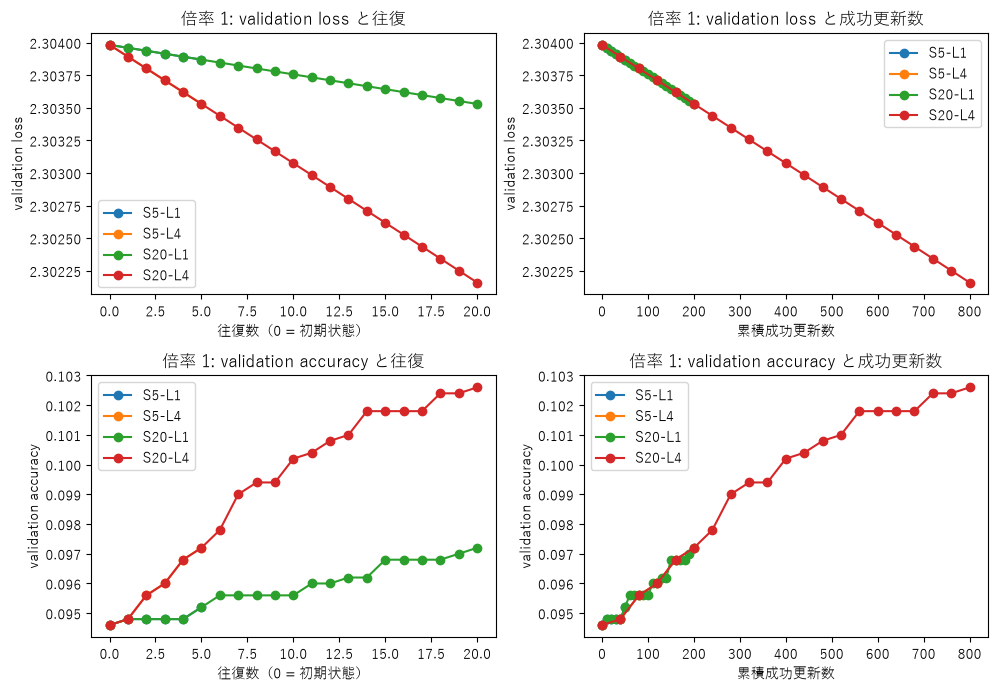

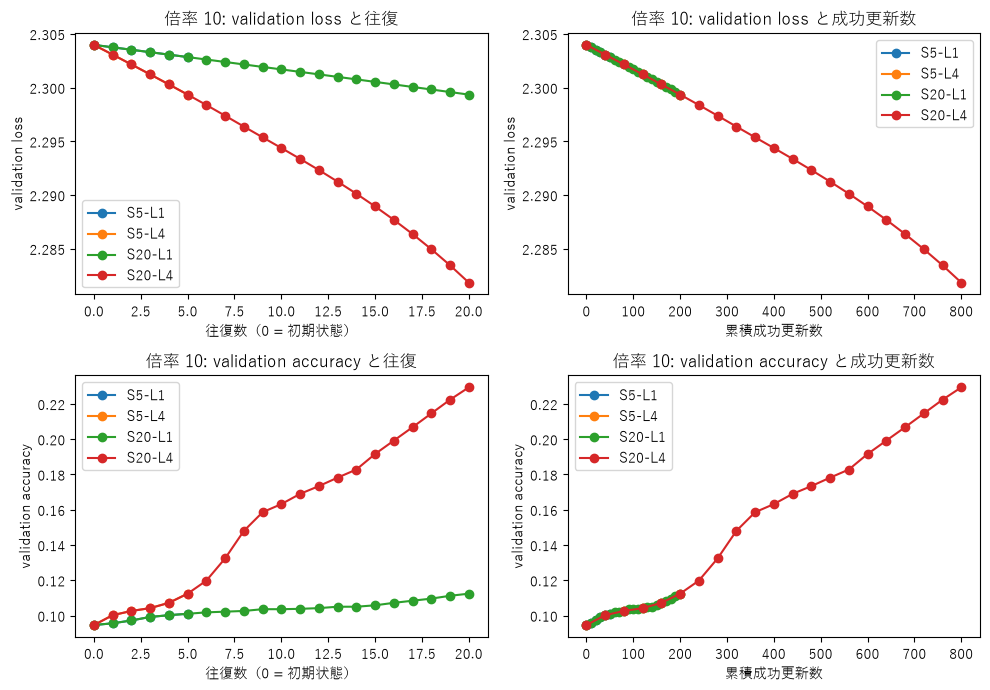

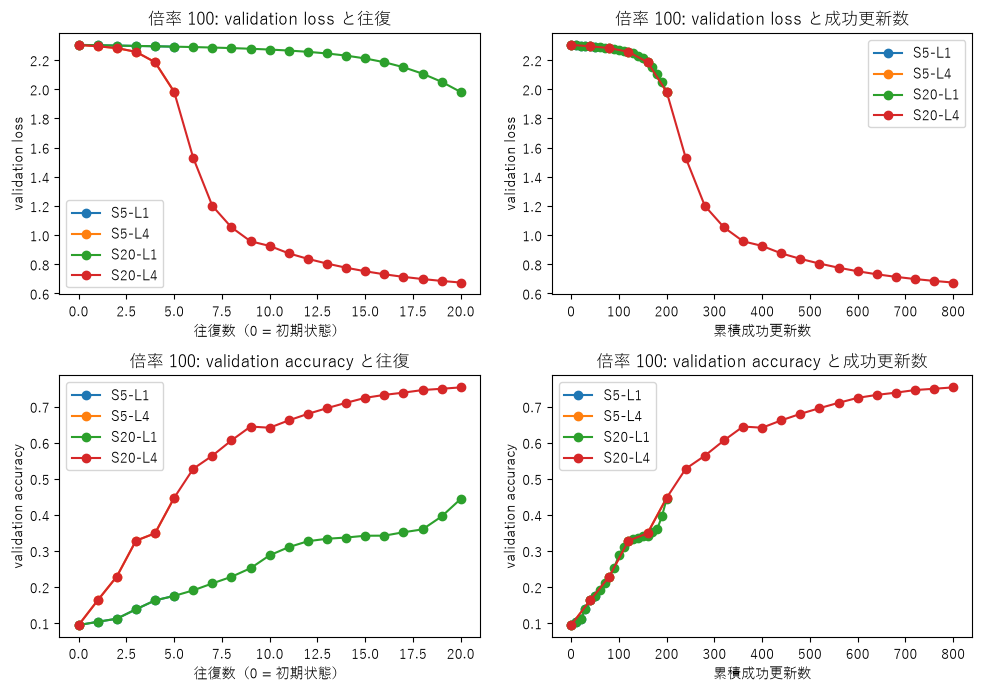

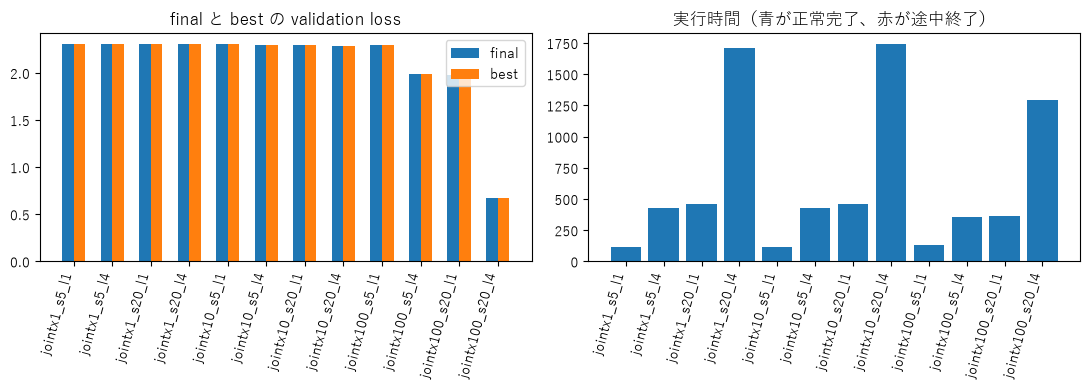

In [23]:
def display_status(rows):
    found = {row["condition_id"]: row for row in rows}
    print("condition_id status completed_sweeps updates final_val best_val best_sweep seconds stop")
    for label in ALL_CONDITION_IDS:
        row = found.get(label)
        if row is None:
            print(label, "未実行")
            continue
        print(
            label,
            row["status"],
            row["completed_sweeps"],
            row["successful_local_updates"],
            row["final_validation_loss"],
            row["best_validation_loss"],
            row["best_sweep"],
            row["seconds_total"],
            row["stop_reason"],
        )


def shared_prefix_rows(rows):
    found = {row["condition_id"]: row for row in rows}
    report = []
    for multiplier in JOINT_LEARNING_RATE_MULTIPLIERS:
        for local_steps in LOCAL_STEPS_LIST:
            short_id = condition_id(multiplier, 5, local_steps)
            long_id = condition_id(multiplier, 20, local_steps)
            item = {
                "short_id": short_id,
                "long_id": long_id,
                "status": "未実行",
            }
            if short_id not in found or long_id not in found:
                report.append(item)
                continue
            short_history = read_history(models_dir / short_id / "history.csv")
            long_history = read_history(models_dir / long_id / "history.csv")
            common = min(len(short_history), len(long_history))
            diffs = []
            for index in range(common):
                for key in ("train_loss", "train_acc", "validation_loss", "validation_acc"):
                    diffs.append(abs(short_history[index][key] - long_history[index][key]))
            item.update(
                {
                    "status": "比較済み",
                    "common_rows": common,
                    "max_abs_diff": max(diffs) if diffs else None,
                }
            )
            report.append(item)
    return report


if not grid_rows:
    print("全12条件は未実行")
    print("smoke run は本実験の完了ではない。")
else:
    display_status(grid_rows)
    prefix_report = shared_prefix_rows(grid_rows)
    print("同じ倍率・local step で最大往復数だけが違う条件の共通履歴:")
    for item in prefix_report:
        print(item)

    by_multiplier = {}
    for row in grid_rows:
        by_multiplier.setdefault(float(row["joint_learning_rate_multiplier"]), []).append(row)
    for multiplier, subset in by_multiplier.items():
        figure, axes = plt.subplots(2, 2, figsize=(10, 7))
        for row in subset:
            history = read_history(models_dir / row["condition_id"] / "history.csv")
            sweeps = [item["sweep"] for item in history]
            updates = [item["cumulative_successful_updates"] for item in history]
            label = f"S{row['max_sweeps']}-L{row['local_steps_per_pair']}"
            axes[0, 0].plot(sweeps, [item["validation_loss"] for item in history], marker="o", label=label)
            axes[0, 1].plot(updates, [item["validation_loss"] for item in history], marker="o", label=label)
            axes[1, 0].plot(sweeps, [item["validation_acc"] for item in history], marker="o", label=label)
            axes[1, 1].plot(updates, [item["validation_acc"] for item in history], marker="o", label=label)
        axes[0, 0].set_title(f"倍率 {multiplier:g}: validation loss と往復")
        axes[0, 1].set_title(f"倍率 {multiplier:g}: validation loss と成功更新数")
        axes[1, 0].set_title(f"倍率 {multiplier:g}: validation accuracy と往復")
        axes[1, 1].set_title(f"倍率 {multiplier:g}: validation accuracy と成功更新数")
        axes[0, 0].set_xlabel("往復数（0 = 初期状態）")
        axes[1, 0].set_xlabel("往復数（0 = 初期状態）")
        axes[0, 1].set_xlabel("累積成功更新数")
        axes[1, 1].set_xlabel("累積成功更新数")
        axes[0, 0].set_ylabel("validation loss")
        axes[0, 1].set_ylabel("validation loss")
        axes[1, 0].set_ylabel("validation accuracy")
        axes[1, 1].set_ylabel("validation accuracy")
        for axis in axes.ravel():
            axis.legend()
        figure.tight_layout()
        figure.savefig(results_dir / f"curves_jointx{multiplier:g}.png", dpi=120)
        plt.show()

    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    positions = list(range(len(grid_rows)))
    labels = [row["condition_id"] for row in grid_rows]
    axes[0].bar(
        [position - 0.15 for position in positions],
        [float(row["final_validation_loss"]) for row in grid_rows],
        width=0.3,
        label="final",
    )
    axes[0].bar(
        [position + 0.15 for position in positions],
        [float(row["best_validation_loss"]) for row in grid_rows],
        width=0.3,
        label="best",
    )
    axes[0].set_xticks(positions)
    axes[0].set_xticklabels(labels, rotation=75, ha="right")
    axes[0].set_title("final と best の validation loss")
    axes[0].legend()
    colors = ["C0" if row["status"] == "正常完了" else "C3" for row in grid_rows]
    axes[1].bar(positions, [float(row["seconds_total"]) for row in grid_rows], color=colors)
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(labels, rotation=75, ha="right")
    axes[1].set_title("実行時間（青が正常完了、赤が途中終了）")
    figure.tight_layout()
    figure.savefig(results_dir / "final_best_and_time.png", dpi=120)
    plt.show()


## 7. 結果の読み方と、本実験を始める手順

final は指定予算の終了時のモデルである。途中終了のときは、予算未完了の最後の正常状態であり、完了した往復とは分けて記録する。best は validation loss が最小だった往復で、初期状態も候補に入る。往復が多い条件は、best を選ぶ機会が多い。最大往復数を比べるときは final を見る。

改善があっても、TT 更新だけの効果ではない。二つの学習率は倍率で連動している。00の checkpoint と初期 state が一致する比較でもない。

本実験を開始する手順は次である。

1. smoke の終了理由、指標、時間見積もりを確認する。
2. 設定セルの `RUN_FULL_GRID` を `True` にする。`RUN_SMOKE` は `False` のままでよい。
3. データ読込から下のセルを実行する。12条件は、それぞれ `initial_stage_c.pt` から作り直される。途中で止まった場合は、同じスイッチのまま再実行すると、集計済みの条件を確認して続きから実行する。
4. 00、01、および `initial_stage_c.pt` は変更しない。

条件ごとの履歴は `models/40_dmrg/10_fashion_mnist_mlp/02_full_batch_sweep_update_budget_grid/<条件ID>/history.csv`、一覧は `results/40_dmrg/10_fashion_mnist_mlp/02_full_batch_sweep_update_budget_grid/condition_summary.csv` に保存される。smoke は同じ分類の `02_full_batch_sweep_update_budget_grid_smoke` にある。
